# Analisis Jangkauan Pos Pemadam Kebakaran — Surabaya Timur
Team 4 · Computer Graphics 2026/2027

Alur: data kejadian → validasi layer → proyeksi EPSG:32749 → buffer pos → spatial join → waktu tempuh rute TomTom (lengang vs ramai) → jawaban pertanyaan proposal (bagian 10).

**Data di `data/`:** `kejadian_sijalinmaja_2026.csv` (SIJALINMAJA, diambil 01-11-2026), `pos_damkar.csv` (`nama, jenis, lon, lat`), dan `kecamatan_surabaya.geojson` (11 kecamatan, dipotong sekali dari batas administrasi HDX `idn_admin_boundaries.gdb.zip`).
API key TomTom disimpan di file `.tomtom_key` atau env `TOMTOM_API_KEY`; tidak dibutuhkan jika `output/tomtom_cache.json` ikut disertakan.

**Perbedaan dengan proposal** (proposal sudah dikumpulkan, jadi dicatat di sini):
- Data kejadian dari SIJALINMAJA [6], bukan Open Data Surabaya [5] yang hanya sampai 2022.
- 7 pos: 5 pos proposal ditambah UPTD II Tambak Rejo dan Mako Pasar Turi, pos tercepat bagi Tambaksari, Kenjeran, dan Genteng. Cek silang dengan OSM ada di bagian 2.
- Rute dari TomTom, bukan Google Maps (proposal hanya menyebutnya sebagai contoh). Jam skenario: 02:00 (lengang), 14:00 (siang, contoh di proposal), 17:00 (puncak sore hasil profil 24 jam).
- Bagian bertanda *(tambahan)* berada di luar proposal dan sudah disetujui.

In [42]:
%pip install -q geopandas matplotlib requests folium


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [43]:
import os, json, re
from datetime import date, datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

DATA = Path("data")
OUT = Path("output"); OUT.mkdir(exist_ok=True)
KECAMATAN_PATH = DATA / "kecamatan_surabaya.geojson"   # hasil potongan, dibuat otomatis dari file HDX
HDX_GDB = [DATA / "idn_admin_boundaries.gdb", DATA / "idn_admin_boundaries.gdb.zip"]   # download dari HDX cod-ab-idn

STUDI = ["Gubeng", "Gunung Anyar", "Mulyorejo", "Rungkut", "Sukolilo", "Tambaksari",
         "Tenggilis Mejoyo", "Bulak", "Kenjeran", "Genteng", "Wonocolo"]
CRS_UTM = "EPSG:32749"
RADIUS_M = {"pembantu": 2500, "rayon": 3500}   # Permen PU 20/PRT/M/2009
TANGGAL_SAMPEL = date(2026, 10, 28)              # hari yang disimulasikan TomTom (Rabu = hari kerja); ganti tanggal untuk hari lain
# Jam skenario {nama: "HH:MM"}; yang pertama = jam pagi pembanding, minimal 2. Satu peta per skenario; nama pakai _ bukan spasi.
# None = jam pagi dan puncak sore dipilih otomatis dari profil 24 jam (bagian 6.1).
JAM_SKENARIO = {"pagi": "07:00", "siang": "14:00", "puncak_sore": "17:00", "malam": "22:00"}
TAHUN = 2026                                     # data kebakaran: SIJALINMAJA, hanya tahun ini
TANGGAL_SNAPSHOT = date(2026, 11, 1)             # tanggal data SIJALINMAJA diambil
BATAS_TEMPUH_MENIT = 5                          # tahap perjalanan; 15 menit = 5 terima panggilan + 5 perjalanan + 5 siapkan alat

def kunci(nama):
    # samakan penulisan nama kecamatan: 'Gunung Anyar' == 'Gununganyar'
    return re.sub(r"[^a-z]", "", str(nama).lower())

In [44]:
import folium
from html import escape
from branca.colormap import LinearColormap
from IPython.display import display

wgs = lambda g: g.to_crs("EPSG:4326")
label = lambda n: re.sub(r"_(\d\d)(\d\d)$", r" \1:\2", n).replace("_", " ")   # "puncak_sore_1700" -> "puncak sore 17:00"

def peta_baru():   # peta difokuskan ke wilayah studi (batas kecamatan STUDI + margin ±4 km)
    minx, miny, maxx, maxy = kec.total_bounds
    m = folium.Map(location=[(miny + maxy) / 2, (minx + maxx) / 2], zoom_start=11, min_zoom=11, max_bounds=True, max_bounds_viscosity=1.0)
    m.fit_bounds([[miny - 0.04, minx - 0.04], [maxy + 0.04, maxx + 0.04]])
    return m

def judul(m, teks):
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;top:8px;left:55px;z-index:9999;background:white;padding:4px 10px;border-radius:4px;'
        f'font:bold 13px sans-serif;box-shadow:0 0 4px gray">{escape(teks)}</div>'))

def legenda(m, teks, item):
    baris = "".join(f'<div><span style="background:{w};opacity:.7;display:inline-block;width:14px;height:14px;margin-right:6px"></span>{escape(k)}</div>'
                    for k, w in item.items())
    m.get_root().html.add_child(folium.Element(
        f'<div style="position:fixed;bottom:25px;left:10px;z-index:9999;background:white;padding:8px 10px;border-radius:4px;'
        f'font:12px sans-serif;box-shadow:0 0 4px gray"><b>{escape(teks)}</b>{baris}</div>'))

def tandai_pos(m):
    for _, r in pos.iterrows():
        folium.Marker((r.geometry.y, r.geometry.x), tooltip=f"{r['nama']} ({r['jenis']})",
                      icon=folium.Icon(color="red", icon="fire-extinguisher", prefix="fa")).add_to(m)

def simpan(m, nama):   # tiap peta juga disimpan sebagai HTML di output/
    m.save(OUT / f"{nama}.html")
    print("Peta tersimpan:", OUT / f"{nama}.html")
    return m

## 1. Data kejadian kebakaran 2026 per kecamatan (SIJALINMAJA)

In [45]:
raw = pd.read_csv(DATA / "kejadian_sijalinmaja_2026.csv")
raw = raw[(raw["tanggal_kejadian"].str[:4] == str(TAHUN)) & raw["nama_kecamatan"].map(kunci).isin({kunci(k) for k in STUDI})]
print(f"{len(raw)} baris bertanggal {TAHUN} di {len(STUDI)} kecamatan studi (SIJALINMAJA, diambil {TANGGAL_SNAPSHOT})")

# Validasi tanggal: kejadian tidak mungkin diinput ke sistem (created_at) sebelum terjadi.
tanggal_input = pd.to_datetime(raw["created_at"], utc=True).dt.tz_convert("Asia/Jakarta").dt.strftime("%Y-%m-%d")
salah_tahun = raw["tanggal_kejadian"] > tanggal_input

# Bukti pendukung: id_api berformat kbk-<hari><bulan><tahun>-..., mis. kbk-892025-... = 8-9-2025
def tahun_id_api(r):
    m = re.match(r"kbk-(\d+)-", str(r["id_api"]))
    t = pd.Timestamp(r["tanggal_kejadian"])
    return next((str(th) for th in (t.year, t.year - 1) if m and m.group(1) == f"{t.day}{t.month}{th}"), "tanpa tanggal")
tahun_api = raw.apply(tahun_id_api, axis=1)
display(pd.crosstab(tahun_api.rename("tahun menurut id_api"),
                    salah_tahun.map({True: "diinput sebelum terjadi", False: "wajar"}).rename("tanggal input")))
print(f"{salah_tahun.sum()} baris dibuang karena diinput ({', '.join(sorted(set(tanggal_input[salah_tahun])))}) sebelum tanggal kejadiannya; "
      f"{(tahun_api[salah_tahun] == str(TAHUN - 1)).sum()} di antaranya menurut id_api sebenarnya kejadian {TAHUN - 1} (salah tulis tahun).")
raw = raw[~salah_tahun]
print(f"Kejadian {TAHUN} yang valid: {len(raw)} ({raw['tanggal_kejadian'].min()} s/d {raw['tanggal_kejadian'].max()})")

kejadian = (raw.assign(Kecamatan=raw["nama_kecamatan"].str.strip().str.title())
            .groupby("Kecamatan").size().rename("jumlah_kejadian").reset_index())
kejadian["key"] = kejadian["Kecamatan"].map(kunci)
print("Kejadian di wilayah studi:", kejadian["jumlah_kejadian"].sum())
kejadian.sort_values("jumlah_kejadian", ascending=False)

155 baris bertanggal 2026 di 11 kecamatan studi (SIJALINMAJA, diambil 2026-11-01)


tanggal input,diinput sebelum terjadi,wajar
tahun menurut id_api,,
2025,35,0
2026,0,100
tanpa tanggal,1,19


36 baris dibuang karena diinput (2026-01-07) sebelum tanggal kejadiannya; 35 di antaranya menurut id_api sebenarnya kejadian 2025 (salah tulis tahun).
Kejadian 2026 yang valid: 119 (2026-01-01 s/d 2026-10-27)
Kejadian di wilayah studi: 119


,Kecamatan,jumlah_kejadian,key
7,Sukolilo,19,sukolilo
0,Bulak,16,bulak
4,Kenjeran,15,kenjeran
3,Gunung Anyar,14,gununganyar
2,Gubeng,11,gubeng
8,Tambaksari,11,tambaksari
1,Genteng,8,genteng
6,Rungkut,8,rungkut
10,Wonocolo,7,wonocolo
5,Mulyorejo,6,mulyorejo


## 2. Validasi layer

In [46]:
def validasi(gdf, id_col, nama):
    assert gdf.crs is not None, f"{nama}: CRS kosong"
    assert not gdf.geometry.is_empty.any() and gdf.geometry.notna().all(), f"{nama}: ada geometri kosong"
    if not gdf.geometry.is_valid.all():
        print(f"{nama}: geometri tidak valid diperbaiki dengan make_valid()")
        gdf = gdf.set_geometry(gdf.geometry.make_valid())
    assert gdf[id_col].is_unique, f"{nama}: {id_col} tidak unik"
    minx, miny, maxx, maxy = gdf.total_bounds   # EPSG:4326, urutan lon lalu lat
    assert 112.5 <= minx and maxx <= 113.0 and -7.5 <= miny and maxy <= -7.1, f"{nama}: koordinat di luar Surabaya / lon-lat tertukar"
    print(f"{nama}: {len(gdf)} fitur, CRS {gdf.crs.to_string()}, bounds {gdf.total_bounds.round(4)}")
    return gdf

### Layer 2 — Batas kecamatan (Polygon)

In [47]:
import pyogrio

if KECAMATAN_PATH.exists():
    kec_all = gpd.read_file(KECAMATAN_PATH)
else:   # sekali saja: potong dari file HDX (layer adm3 = kecamatan), bbox Surabaya supaya tidak memuat seluruh Indonesia
    gdb = next((p for p in HDX_GDB if p.exists()), None)
    assert gdb, f"Taruh file HDX di salah satu: {[str(p) for p in HDX_GDB]}"
    layer = next(n for n, _ in pyogrio.list_layers(gdb) if "adm3" in n.lower() or "admin3" in n.lower())
    kec_all = gpd.read_file(gdb, layer=layer, bbox=(112.55, -7.40, 112.90, -7.15))
# nama seperti Genteng/Sukolilo juga ada di kabupaten lain, jadi filter Kota Surabaya dulu
kec_all = kec_all[kec_all["adm2_name"].str.contains("Surabaya", na=False)]

kec = kec_all.assign(key=kec_all["adm3_name"].map(kunci))
kec = kec[kec["key"].isin({kunci(k) for k in STUDI})].dissolve(by="key").reset_index()
hilang = {kunci(k) for k in STUDI} - set(kec["key"])
assert not hilang, f"Kecamatan tidak ditemukan: {hilang}. Jika STUDI diubah, hapus {KECAMATAN_PATH} dan sediakan file HDX agar dipotong ulang."
if not KECAMATAN_PATH.exists():
    kec.to_file(KECAMATAN_PATH, driver="GeoJSON")   # simpan kecamatan STUDI saja; file HDX boleh dihapus setelah ini

kec = kec.merge(kejadian[["key", "Kecamatan", "jumlah_kejadian"]], on="key", how="left")[["key", "Kecamatan", "jumlah_kejadian", "geometry"]]
kec = validasi(kec.to_crs("EPSG:4326"), "key", "Kecamatan")

Kecamatan: 11 fitur, CRS EPSG:4326, bounds [112.7293  -7.3465 112.8468  -7.1957]


### Layer 1 — Titik pos Damkar (Point)

In [48]:
pos_df = pd.read_csv(DATA / "pos_damkar.csv")
pos_df["jenis"] = pos_df["jenis"].str.strip().str.lower()
assert pos_df[["lon", "lat"]].notna().all().all(), "Isi dulu lon/lat semua pos di data/pos_damkar.csv"
assert pos_df["jenis"].isin(RADIUS_M).all(), f"jenis harus salah satu dari {list(RADIUS_M)}"
assert len(pos_df) >= 4, "Analisis memakai minimal 4 pos"

# validasi() juga mengecek batas koordinat, sehingga lon/lat yang tertukar akan ketahuan
pos = gpd.GeoDataFrame(pos_df, geometry=gpd.points_from_xy(pos_df["lon"], pos_df["lat"]), crs="EPSG:4326")
pos = validasi(pos, "nama", "Pos Damkar")
pos

Pos Damkar: 7 fitur, CRS EPSG:4326, bounds [112.7364  -7.3367 112.8017  -7.2318]


,nama,jenis,lon,lat,geometry
0,Rayon/UPTD III (SIER),rayon,112.754070,-7.336707,POINT (112.75407 -7.33671)
1,Pos Kali Rungkut,pembantu,112.769998,-7.322148,POINT (112.77 -7.32215)
2,Pos Sukolilo (Keputih),pembantu,112.801729,-7.295276,POINT (112.80173 -7.29528)
3,Pos Bulak,pembantu,112.785459,-7.231831,POINT (112.78546 -7.23183)
4,UPTD II Tambak Rejo,rayon,112.759729,-7.243086,POINT (112.75973 -7.24309)
5,Mako Pasar Turi,rayon,112.736357,-7.244985,POINT (112.73636 -7.24498)
6,Pos Menur,pembantu,112.762941,-7.278230,POINT (112.76294 -7.27823)


#### Cek silang daftar pos dengan OpenStreetMap (`amenity=fire_station`)
Daftar pos di `pos_damkar.csv` dicocokkan dengan pos pemadam kebakaran di OSM sekitar wilayah studi; dianggap sama jika jaraknya ≤ 200 m. Hasil query disimpan ke `data/osm_fire_station.json`, jadi run ulang tidak perlu internet.

Pos OSM yang tidak dipakai (Pos Jambangan dan Surabaya IV) berada di luar wilayah studi, tidak disebut di proposal, dan tidak pernah menjadi pos tercepat untuk kecamatan studi.
Contohnya, rute dari Pos Jambangan ke Wonocolo (kecamatan studi terdekatnya) 11,2 menit, sedangkan dari Rayon/UPTD III 8,1 menit pada 02:00. Keduanya hanya ditampilkan sebagai ikon abu-abu di peta gabungan.

In [49]:
w, s, e, n = kec.total_bounds + [-0.05, -0.05, 0.05, 0.05]   # wilayah studi + margin ±5 km
bbox = [round(float(v), 2) for v in (s, w, n, e)]                # urutan Overpass: selatan, barat, utara, timur
OSM_PATH = DATA / "osm_fire_station.json"
osm_json = json.loads(OSM_PATH.read_text()) if OSM_PATH.exists() else {}
if osm_json.get("bbox") != bbox:   # belum pernah di-query, atau wilayah studi berubah
    q = f'[out:json][timeout:60];nwr["amenity"="fire_station"]({",".join(map(str, bbox))});out center tags;'
    r = requests.post("https://overpass-api.de/api/interpreter", data={"data": q}, headers={"User-Agent": "AFL2-Comgraph"}, timeout=90)
    assert r.ok, f"Overpass error {r.status_code}: {r.text[:200]}"
    osm_json = {"bbox": bbox, "elements": r.json()["elements"]}
    OSM_PATH.write_text(json.dumps(osm_json))
el = osm_json["elements"]
xy = [(e["lon"], e["lat"]) if "lon" in e else (e["center"]["lon"], e["center"]["lat"]) for e in el]
osm = gpd.GeoDataFrame({"nama_osm": [e["tags"].get("name", "(tanpa nama)") for e in el]},
                       geometry=gpd.points_from_xy(*zip(*xy)), crs="EPSG:4326")

osm_m, pos_cek = osm.to_crs(CRS_UTM), pos.to_crs(CRS_UTM)
jarak = [pos_cek.distance(g) for g in osm_m.geometry]
osm["pos_di_csv"] = [pos_cek.loc[d.idxmin(), "nama"] if d.min() <= 200 else "-" for d in jarak]
osm["jarak_ke_pos_csv_m"] = [round(d.min()) for d in jarak]
osm["jarak_ke_wilayah_studi_km"] = (osm_m.distance(kec.to_crs(CRS_UTM).union_all()) / 1000).round(2)

print(f"{len(osm)} pos di OSM sekitar wilayah studi, {(osm['pos_di_csv'] != '-').sum()} cocok dengan pos di CSV.")
print("Pos di CSV yang tidak ada di OSM (koordinat diverifikasi manual):", ", ".join(sorted(set(pos["nama"]) - set(osm["pos_di_csv"]))) or "-")
osm_lain = osm[osm["pos_di_csv"] == "-"]   # ditampilkan sebagai layer abu-abu di peta gabungan (bagian 8)
print("Pos di OSM yang tidak dipakai dalam analisis:", ", ".join(osm_lain["nama_osm"]) or "-")
osm.drop(columns="geometry")

8 pos di OSM sekitar wilayah studi, 6 cocok dengan pos di CSV.
Pos di CSV yang tidak ada di OSM (koordinat diverifikasi manual): Pos Menur
Pos di OSM yang tidak dipakai dalam analisis: Dinas Kebakaran Pos Jambangan, Pemadam Kebakaran Surabaya IV


,nama_osm,pos_di_csv,jarak_ke_pos_csv_m,jarak_ke_wilayah_studi_km
0,Pemadam Kebakaran Kecamatan Bulak,Pos Bulak,0,0.00
1,Pos Pembantu Pemadam Kebakaran Kota Surabaya,Pos Sukolilo (Keputih),0,0.00
2,Dinas Kebakaran Pos Jambangan,-,4736,2.07
3,Dinas Kebakaran UPTD 3 Surabaya,Rayon/UPTD III (SIER),0,0.00
4,Dinas Kebakaran UPTD II Surabaya Utara Tambak ...,UPTD II Tambak Rejo,2,0.11
5,Pemadam Kebakaran Surabaya IV,-,6892,4.18
6,Dinas Pemadam Kebakaran Pos Kali Rungkut,Pos Kali Rungkut,0,0.00
7,Dinas Kebakaran Kota Surabaya,Mako Pasar Turi,2,0.69


## 3. Proyeksi ke UTM 49S (meter)

In [50]:
kec_m = kec.to_crs(CRS_UTM)
pos_m = pos.to_crs(CRS_UTM)
print(f"{CRS_UTM}: satuan {kec_m.crs.axis_info[0].unit_name}")

EPSG:32749: satuan metre


## 4. Operasi 1 — Buffer zona jangkauan

In [51]:
pos_m["radius_m"] = pos_m["jenis"].map(RADIUS_M)
buffer_m = pos_m.copy()
buffer_m["geometry"] = pos_m.buffer(pos_m["radius_m"])
buffer_m[["nama", "jenis", "radius_m"]]

,nama,jenis,radius_m
0,Rayon/UPTD III (SIER),rayon,3500
1,Pos Kali Rungkut,pembantu,2500
2,Pos Sukolilo (Keputih),pembantu,2500
3,Pos Bulak,pembantu,2500
4,UPTD II Tambak Rejo,rayon,3500
5,Mako Pasar Turi,rayon,3500
6,Pos Menur,pembantu,2500


## 5. Operasi 2 — Spatial join & status jangkauan

In [52]:
def status_jangkauan(kec_m, buffer_m):
    hit = gpd.sjoin(kec_m[["key", "geometry"]], buffer_m[["nama", "geometry"]], predicate="intersects")
    # satu kecamatan bisa cocok dengan beberapa buffer -> dihitung per kecamatan unik
    pos_per_kec = hit.groupby("key")["nama"].apply(lambda s: ", ".join(sorted(s)))
    centroid_masuk = kec_m.centroid.within(buffer_m.union_all())
    status = pd.Series("belum terjangkau", index=kec_m.index)
    status[kec_m["key"].isin(pos_per_kec.index)] = "terjangkau sebagian"
    status[centroid_masuk] = "terjangkau"
    return status, kec_m["key"].map(pos_per_kec).fillna("-")

kec_m["status"], kec_m["pos_beririsan"] = status_jangkauan(kec_m, buffer_m)
tabel_jarak = kec_m[["Kecamatan", "jumlah_kejadian", "status", "pos_beririsan"]].sort_values("jumlah_kejadian", ascending=False)
tabel_jarak

,Kecamatan,jumlah_kejadian,status,pos_beririsan
7,Sukolilo,19,terjangkau,"Pos Kali Rungkut, Pos Menur, Pos Sukolilo (Kep..."
0,Bulak,16,terjangkau,"Pos Bulak, UPTD II Tambak Rejo"
4,Kenjeran,15,terjangkau,"Mako Pasar Turi, Pos Bulak, UPTD II Tambak Rejo"
3,Gunung Anyar,14,terjangkau sebagian,"Pos Kali Rungkut, Rayon/UPTD III (SIER)"
2,Gubeng,11,terjangkau,"Mako Pasar Turi, Pos Kali Rungkut, Pos Menur, ..."
8,Tambaksari,11,terjangkau,"Mako Pasar Turi, Pos Bulak, Pos Menur, UPTD II..."
1,Genteng,8,terjangkau,"Mako Pasar Turi, Pos Menur, UPTD II Tambak Rejo"
6,Rungkut,8,terjangkau sebagian,"Pos Kali Rungkut, Pos Sukolilo (Keputih), Rayo..."
10,Wonocolo,7,terjangkau,"Pos Kali Rungkut, Rayon/UPTD III (SIER)"
5,Mulyorejo,6,terjangkau sebagian,"Pos Bulak, Pos Menur, Pos Sukolilo (Keputih), ..."


In [53]:
warna = {"terjangkau": "#4caf50", "terjangkau sebagian": "#ffc107", "belum terjangkau": "#e53935"}
m = peta_baru()
folium.GeoJson(wgs(kec_m[["Kecamatan", "jumlah_kejadian", "status", "pos_beririsan", "geometry"]]),
               style_function=lambda f: {"fillColor": warna[f["properties"]["status"]], "fillOpacity": 0.55, "color": "black", "weight": 1},
               tooltip=folium.GeoJsonTooltip(fields=["Kecamatan", "jumlah_kejadian", "status", "pos_beririsan"],
                                             aliases=["Kecamatan", f"Kejadian {TAHUN}", "Status", "Pos beririsan"])).add_to(m)
folium.GeoJson(wgs(buffer_m[["nama", "radius_m", "geometry"]]),   # garis saja (tanpa isi) supaya tooltip kecamatan tetap bisa dibaca
               style_function=lambda f: {"color": "navy", "weight": 1.5, "dashArray": "6,6", "fill": False},
               tooltip=folium.GeoJsonTooltip(fields=["nama", "radius_m"], aliases=["Pos", "Radius (m)"])).add_to(m)
tandai_pos(m)
judul(m, f"Jangkauan buffer pos Damkar vs kejadian kebakaran {TAHUN}")
legenda(m, "Status jangkauan", warna)
simpan(m, "peta_jangkauan_buffer")

Peta tersimpan: output/peta_jangkauan_buffer.html


## 6. Fitur tambahan — Waktu tempuh berdasarkan jam (TomTom)
Semua perhitungan memakai jaringan jalan dan lalu lintas historis TomTom pada `TANGGAL_SAMPEL` (hari kerja), bukan garis lurus.
1. **Profil 24 jam** *(tambahan)*: jam lengang dan jam ramai dipilih dari data, bukan ditebak.
2. **Waktu tempuh rute**: dari setiap pos ke centroid setiap kecamatan, diambil pos tercepat, dibandingkan dengan batas 5 menit.

Semua respons disimpan di `output/tomtom_cache.json`; run ulang hanya mengirim request yang belum ada di cache.

In [54]:
import time
from getpass import getpass

WIB = ZoneInfo("Asia/Jakarta")
CACHE = OUT / "tomtom_cache.json"
cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}
sesi = requests.Session()   # pakai ulang koneksi TLS, jauh lebih cepat dari requests.get per request
_key = None

def tomtom(endpoint, lokasi, **params):
    global _key
    ck = f"{endpoint}/{lokasi}?{json.dumps(params, sort_keys=True)}"
    if ck not in cache:
        if _key is None:
            KEY_FILE = Path(".tomtom_key")   # file lokal, jangan ikut dikumpulkan
            _key = os.environ.get("TOMTOM_API_KEY") or (KEY_FILE.read_text().strip() if KEY_FILE.exists() else getpass("TomTom API key: "))
        r = sesi.get(f"https://api.tomtom.com/routing/1/{endpoint}/{lokasi}/json", timeout=30,
                     params={"key": _key, "travelMode": "car", "traffic": "true", **params})
        assert r.ok, f"TomTom error {r.status_code}: {r.text[:200]}"
        cache[ck] = r.json()
        time.sleep(0.2)   # batas request per detik akun gratis
    return cache[ck]

def simpan_cache():
    CACHE.write_text(json.dumps(cache))

def berangkat(jam):   # jam: angka 0-23 (profil 24 jam) atau datetime.time dari JAM_SKENARIO
    t = datetime.min.time().replace(hour=jam) if isinstance(jam, int) else jam
    return datetime.combine(TANGGAL_SAMPEL, t, tzinfo=WIB).isoformat()

def rute_json(asal, tujuan, jam):
    return tomtom("calculateRoute", f"{asal.y},{asal.x}:{tujuan.y},{tujuan.x}", routeType="fastest", departAt=berangkat(jam))["routes"][0]

def rute(asal, tujuan, jam):   # waktu tempuh (menit)
    return rute_json(asal, tujuan, jam)["summary"]["travelTimeInSeconds"] / 60

def garis_rute(asal, tujuan, jam):   # jalur jalan [(lat, lon), ...] untuk folium.PolyLine
    return [(t["latitude"], t["longitude"]) for leg in rute_json(asal, tujuan, jam)["legs"] for t in leg["points"]]

tujuan = kec_m.centroid.to_crs("EPSG:4326")

### 6.1 Profil waktu tempuh 24 jam: memilih jam skenario *(tambahan)*

Hasil profil: lengang 02:00, puncak pagi 08:00, puncak sore 17:00
Skenario terpilih: pagi 07:00, siang 14:00, puncak sore 17:00, malam 22:00


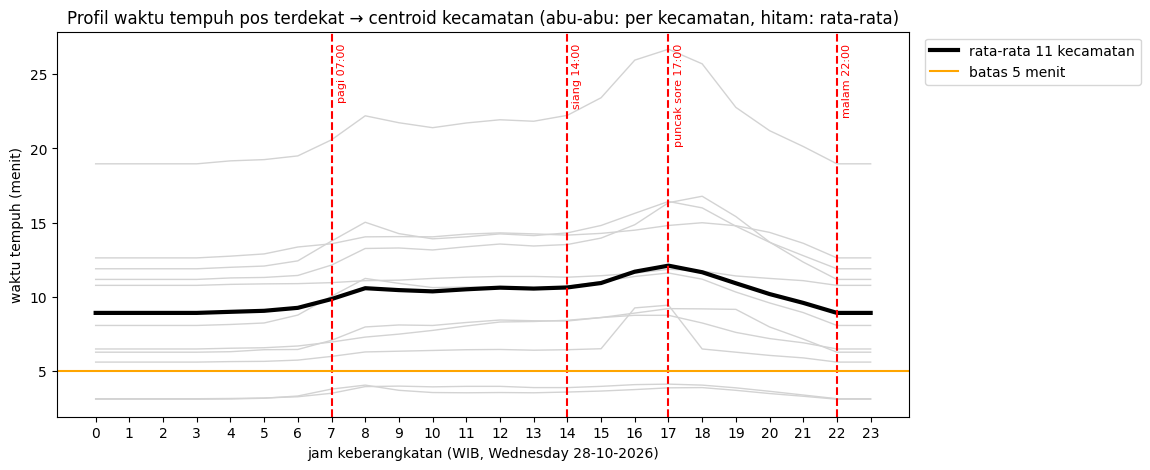

In [55]:
# sampel: pos terdekat (garis lurus) ke centroid tiap kecamatan, 11 rute x 24 jam
terdekat_lurus = [pos_m.distance(c).idxmin() for c in kec_m.centroid]
profil = pd.DataFrame({jam: [rute(pos.geometry[i], t, jam) for i, t in zip(terdekat_lurus, tujuan)] for jam in range(24)},
                      index=kec_m["Kecamatan"])
simpan_cache()

rata = profil.mean()
# 00.00-03.00 biasanya sama lengangnya; kalau seri pilih 02.00 sesuai proposal
JAM_LENGANG = min(range(6), key=lambda j: (round(rata[j], 1), abs(j - 2)))
JAM_PAGI = int(rata.loc[5:11].idxmax())
JAM_SORE = int(rata.loc[12:20].idxmax())
print(f"Hasil profil: lengang {JAM_LENGANG:02d}:00, puncak pagi {JAM_PAGI:02d}:00, puncak sore {JAM_SORE:02d}:00")
pilihan = JAM_SKENARIO or {"lengang": f"{JAM_LENGANG:02d}:00", "puncak_pagi": f"{JAM_PAGI:02d}:00", "puncak_sore": f"{JAM_SORE:02d}:00"}

def baca_jam(teks):
    try:
        return datetime.strptime(teks, "%H:%M").time()
    except (TypeError, ValueError):
        raise ValueError(f'JAM_SKENARIO: tulis jam sebagai teks "HH:MM", mis. "06:00" (dapat: {teks!r})') from None

SKENARIO = {f"{nama}_{t:%H%M}": t for nama, t in ((n, baca_jam(j)) for n, j in pilihan.items())}
assert len(set(SKENARIO.values())) >= 2, "JAM_SKENARIO: minimal 2 jam yang berbeda; yang pertama = jam lengang pembanding"
print("Skenario terpilih:", ", ".join(label(n) for n in SKENARIO))

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(profil.columns, profil.T.values, color="lightgray", linewidth=1)   # tanpa label: tidak masuk legend
ax.plot(rata.index, rata.values, color="black", linewidth=3, label=f"rata-rata {len(STUDI)} kecamatan")
for nama, t in SKENARIO.items():
    x = t.hour + t.minute / 60
    ax.axvline(x, color="red", linestyle="--")
    ax.text(x + 0.15, 0.97, label(nama), transform=ax.get_xaxis_transform(), rotation=90, va="top", fontsize=8, color="red")
ax.axhline(BATAS_TEMPUH_MENIT, color="orange", label=f"batas {BATAS_TEMPUH_MENIT} menit")
ax.set_xticks(range(24))
ax.set_xlabel(f"jam keberangkatan (WIB, {TANGGAL_SAMPEL:%A %d-%m-%Y})")
ax.set_ylabel("waktu tempuh (menit)")
ax.set_title("Profil waktu tempuh pos terdekat → centroid kecamatan (abu-abu: per kecamatan, hitam: rata-rata)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
fig.savefig(OUT / "profil_waktu_tempuh_24jam.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.2 Waktu tempuh rute pos tercepat per kecamatan
Untuk setiap kecamatan dan setiap jam skenario, waktu tempuh dihitung dari **semua** pos ke centroid kecamatan, lalu diambil pos yang **tercepat** (unit yang paling dulu bisa tiba).
Waktu itu dibandingkan dengan batas **5 menit**, yaitu porsi *perjalanan* dari waktu tanggap 15 menit (Permen PU 20/2009; pembagian 5 + 5 + 5 menit menurut studi Unesa [3]).

Kolom `keterangan_batas` mengelompokkan hasilnya:
- **≤ 5 menit di semua jam**: memenuhi batas, baik saat lengang maupun ramai.
- **lewat batas hanya saat ramai (kemacetan)**: memenuhi batas saat jalan lengang, tetapi tidak saat ramai. Ini yang di proposal disebut *"memenuhi batas saat jalan lengang tetapi tidak saat jalan ramai"*; penyebabnya kemacetan.
- **lewat batas sejak jalan lengang (jarak/posisi pos)**: tetap lebih dari 5 menit walaupun jalan kosong, jadi penyebab utamanya jarak/posisi pos, bukan kemacetan.

`tambah_menit_terburuk` = tambahan waktu di jam paling ramai dibanding jam lengang (dampak kemacetan).

Peta per skenario: warna kecamatan = menit pos tercepat (garis batas merah tebal = lebih dari 5 menit), garis = jalur jalan dari pos tercepat ke centroid kecamatan (titik hitam).

In [56]:
rute_df = pd.DataFrame([{"skenario": nama, "pos": pn, "key": k, "menit": rute(pg, t, jam)}
                        for nama, jam in SKENARIO.items()
                        for pn, pg in zip(pos["nama"], pos.geometry)
                        for k, t in zip(kec_m["key"], tujuan)])
simpan_cache()

tempuh = kec_m[["key", "Kecamatan", "jumlah_kejadian", "status"]].copy()
for nama in SKENARIO:
    t = rute_df[rute_df["skenario"] == nama].reset_index(drop=True)
    terdekat = t.loc[t.groupby("key")["menit"].idxmin()].set_index("key")   # pos tercepat per kecamatan
    tempuh[f"menit_{nama}"] = tempuh["key"].map(terdekat["menit"]).round(1)
    tempuh[f"pos_{nama}"] = tempuh["key"].map(terdekat["pos"])
    tempuh[f"ok_{nama}"] = tempuh[f"menit_{nama}"] <= BATAS_TEMPUH_MENIT

lengang, *ramai = SKENARIO
tempuh["tambah_menit_terburuk"] = (tempuh[[f"menit_{p}" for p in ramai]].max(axis=1) - tempuh[f"menit_{lengang}"]).round(1)

def keterangan(r):
    if not r[f"ok_{lengang}"]:
        return "lewat batas sejak jalan lengang (jarak/posisi pos)"
    if not all(r[f"ok_{p}"] for p in ramai):
        return "lewat batas hanya saat ramai (kemacetan)"
    return f"≤ {BATAS_TEMPUH_MENIT} menit di semua jam"

tempuh["keterangan_batas"] = tempuh.apply(keterangan, axis=1)
ringkasan = tempuh.drop(columns="key").sort_values("jumlah_kejadian", ascending=False)
ringkasan.to_csv(OUT / "ringkasan_per_kecamatan.csv", index=False)
ringkasan

,Kecamatan,jumlah_kejadian,status,menit_pagi_0700,pos_pagi_0700,ok_pagi_0700,menit_siang_1400,pos_siang_1400,ok_siang_1400,menit_puncak_sore_1700,pos_puncak_sore_1700,ok_puncak_sore_1700,menit_malam_2200,pos_malam_2200,ok_malam_2200,tambah_menit_terburuk,keterangan_batas
7,Sukolilo,19,terjangkau,3.8,Pos Sukolilo (Keputih),True,3.6,Pos Sukolilo (Keputih),True,3.9,Pos Sukolilo (Keputih),True,3.1,Pos Sukolilo (Keputih),True,0.1,≤ 5 menit di semua jam
0,Bulak,16,terjangkau,11.0,Pos Bulak,False,11.3,Pos Bulak,False,11.9,Pos Bulak,False,10.8,Pos Bulak,False,0.9,lewat batas sejak jalan lengang (jarak/posisi ...
4,Kenjeran,15,terjangkau,13.1,UPTD II Tambak Rejo,False,14.2,Pos Bulak,False,14.8,Pos Bulak,False,11.9,UPTD II Tambak Rejo,False,1.7,lewat batas sejak jalan lengang (jarak/posisi ...
3,Gunung Anyar,14,terjangkau sebagian,12.2,Pos Kali Rungkut,False,13.5,Pos Kali Rungkut,False,16.4,Pos Kali Rungkut,False,11.2,Pos Kali Rungkut,False,4.2,lewat batas sejak jalan lengang (jarak/posisi ...
2,Gubeng,11,terjangkau,3.5,Pos Menur,True,3.9,Pos Menur,True,4.1,Pos Menur,True,3.2,Pos Menur,True,0.6,≤ 5 menit di semua jam
8,Tambaksari,11,terjangkau,7.1,UPTD II Tambak Rejo,False,8.4,UPTD II Tambak Rejo,False,9.2,UPTD II Tambak Rejo,False,6.3,UPTD II Tambak Rejo,False,2.1,lewat batas sejak jalan lengang (jarak/posisi ...
1,Genteng,8,terjangkau,7.0,Mako Pasar Turi,False,8.4,Mako Pasar Turi,False,8.8,Mako Pasar Turi,False,6.5,Mako Pasar Turi,False,1.8,lewat batas sejak jalan lengang (jarak/posisi ...
6,Rungkut,8,terjangkau sebagian,12.8,Pos Kali Rungkut,False,13.8,Pos Kali Rungkut,False,14.9,Pos Kali Rungkut,False,12.1,Pos Kali Rungkut,False,2.1,lewat batas sejak jalan lengang (jarak/posisi ...
10,Wonocolo,7,terjangkau,10.0,Rayon/UPTD III (SIER),False,10.7,Rayon/UPTD III (SIER),False,11.6,Rayon/UPTD III (SIER),False,8.1,Rayon/UPTD III (SIER),False,1.6,lewat batas sejak jalan lengang (jarak/posisi ...
5,Mulyorejo,6,terjangkau sebagian,13.8,Pos Sukolilo (Keputih),False,14.3,Pos Sukolilo (Keputih),False,16.4,Pos Sukolilo (Keputih),False,11.9,Pos Sukolilo (Keputih),False,2.6,lewat batas sejak jalan lengang (jarak/posisi ...


In [57]:
peta = kec_m.merge(tempuh.drop(columns=["Kecamatan", "jumlah_kejadian", "status"]), on="key")
vmax = peta[[f"menit_{s}" for s in SKENARIO]].max().max()
skala_menit = lambda: LinearColormap(["green", "yellow", "red"], vmin=0, vmax=vmax, caption="Waktu tempuh rute pos tercepat (menit)")
warna_menit = skala_menit()
geom_pos = dict(zip(pos["nama"], pos.geometry))
geom_tujuan = dict(zip(kec_m["key"], tujuan))

def tambah_rute(target, nama, jam):   # jalur pos tercepat -> centroid tiap kecamatan; dipakai juga di peta gabungan
    for k, p, kec_nama, menit in zip(tempuh["key"], tempuh[f"pos_{nama}"], tempuh["Kecamatan"], tempuh[f"menit_{nama}"]):
        folium.PolyLine(garis_rute(geom_pos[p], geom_tujuan[k], jam), color=warna_menit(menit), weight=5, opacity=0.9,
                        tooltip=f"{p} → {kec_nama}: {menit} menit ({label(nama)})").add_to(target)

for nama, jam in SKENARIO.items():
    kolom, ok = f"menit_{nama}", f"ok_{nama}"
    m = peta_baru()
    folium.GeoJson(wgs(peta[["Kecamatan", "jumlah_kejadian", kolom, f"pos_{nama}", ok, "geometry"]]),
                   style_function=lambda f, k=kolom, o=ok: {"fillColor": warna_menit(f["properties"][k]), "fillOpacity": 0.4,
                                                            "color": "black" if f["properties"][o] else "red",   # garis merah tebal = lewat batas
                                                            "weight": 1 if f["properties"][o] else 3},
                   tooltip=folium.GeoJsonTooltip(fields=["Kecamatan", "jumlah_kejadian", kolom, f"pos_{nama}"],
                                                 aliases=["Kecamatan", f"Kejadian {TAHUN}", f"Menit ({label(nama)})", "Pos tercepat"])).add_to(m)
    tambah_rute(m, nama, jam)
    for kec_nama, c in zip(kec_m["Kecamatan"], tujuan):
        folium.CircleMarker((c.y, c.x), radius=4, color="black", fill=True, fill_opacity=1, tooltip=f"Centroid {kec_nama}").add_to(m)
    tandai_pos(m)
    skala_menit().add_to(m)
    judul(m, f"Waktu tempuh & rute pos tercepat, {label(nama)} (garis merah: lebih dari {BATAS_TEMPUH_MENIT} menit)")
    display(simpan(m, f"peta_waktu_tempuh_{nama}"))
simpan_cache()

print(f"Waktu tempuh pos tercepat vs batas {BATAS_TEMPUH_MENIT} menit:")
for ket in [f"≤ {BATAS_TEMPUH_MENIT} menit di semua jam", "lewat batas hanya saat ramai (kemacetan)", "lewat batas sejak jalan lengang (jarak/posisi pos)"]:
    print(f"- {ket}: {', '.join(tempuh.loc[tempuh['keterangan_batas'] == ket, 'Kecamatan']) or 'tidak ada'}")

Peta tersimpan: output/peta_waktu_tempuh_pagi_0700.html


Peta tersimpan: output/peta_waktu_tempuh_siang_1400.html


Peta tersimpan: output/peta_waktu_tempuh_puncak_sore_1700.html


Peta tersimpan: output/peta_waktu_tempuh_malam_2200.html


Waktu tempuh pos tercepat vs batas 5 menit:
- ≤ 5 menit di semua jam: Gubeng, Sukolilo
- lewat batas hanya saat ramai (kemacetan): tidak ada
- lewat batas sejak jalan lengang (jarak/posisi pos): Bulak, Genteng, Gunung Anyar, Kenjeran, Mulyorejo, Rungkut, Tambaksari, Tenggilis Mejoyo, Wonocolo


## 7. Titik kejadian sebenarnya vs buffer *(tambahan)*
Proposal menyebut "lokasi kejadian yang sebenarnya" sebagai pengembangan berikutnya. Bagian ini menguji berapa persen kejadian 2026 (titik koordinat SIJALINMAJA)
yang jatuh di dalam buffer pos (2,5 km pembantu, 3,5 km rayon). Kecamatan tiap titik ditentukan dari posisinya (point-in-polygon).

In [58]:
titik = gpd.GeoDataFrame(raw, geometry=gpd.points_from_xy(raw["lon"], raw["lat"]), crs="EPSG:4326").to_crs(CRS_UTM)   # raw dari bagian 1
n_awal = len(titik)
titik = gpd.sjoin(titik, kec_m[["key", "Kecamatan", "geometry"]], predicate="within").drop(columns="index_right")
beda = (titik["key"] != titik["nama_kecamatan"].map(kunci)).sum()
print(f"{len(titik)} dari {n_awal} titik {TAHUN} di dalam {len(STUDI)} kecamatan; {beda} titik tercatat di kecamatan tetangga (dekat batas)")

titik["dalam_buffer"] = titik.within(buffer_m.union_all())
persen = lambda s: round(s.mean() * 100, 1)
cakupan = titik.groupby("Kecamatan").agg(kejadian=("id", "size"), persen_dalam_buffer=("dalam_buffer", persen))
cakupan.loc["TOTAL"] = [len(titik), persen(titik["dalam_buffer"])]
cakupan.to_csv(OUT / f"cakupan_titik_{TAHUN}.csv")
cakupan.sort_values("kejadian", ascending=False)

118 dari 119 titik 2026 di dalam 11 kecamatan; 0 titik tercatat di kecamatan tetangga (dekat batas)


,kejadian,persen_dalam_buffer
Kecamatan,,
TOTAL,118.0,78.8
Sukolilo,19.0,100.0
Bulak,16.0,81.2
Kenjeran,15.0,80.0
Gunung Anyar,13.0,7.7
Gubeng,11.0,100.0
Tambaksari,11.0,100.0
Genteng,8.0,100.0
Rungkut,8.0,62.5


## 8. Peta gabungan interaktif *(tambahan)*
Semua layer dalam satu peta; nyalakan/matikan lewat kontrol layer di kanan atas. Arahkan kursor ke kecamatan, rute, atau titik untuk detail. Semua peta juga tersimpan sebagai HTML di `output/` dan bisa dibuka di browser tanpa Python.

In [59]:
m = peta_baru()

info = kec_m[["key", "geometry"]].merge(tempuh, on="key")
kolom = ["Kecamatan", "jumlah_kejadian", "status"] + [f"menit_{n}" for n in SKENARIO]
alias = ["Kecamatan", f"Kejadian {TAHUN}", "Status buffer"] + [f"Menit {label(n)}" for n in SKENARIO]
choro = folium.Choropleth(wgs(info[["key", "geometry"] + kolom]), data=info, columns=["key", "jumlah_kejadian"], key_on="feature.properties.key",
                          fill_color="YlOrRd", fill_opacity=0.45, line_opacity=0.8, legend_name=f"Jumlah kejadian kebakaran {TAHUN}",
                          name=f"Kejadian {TAHUN} per kecamatan").add_to(m)
choro.geojson.add_child(folium.GeoJsonTooltip(fields=kolom, aliases=alias))

folium.GeoJson(wgs(buffer_m[["nama", "radius_m", "geometry"]]), name="Buffer (garis lurus)",
               style_function=lambda f: {"color": "gray", "dashArray": "6,6", "weight": 1, "fill": False},
               tooltip=folium.GeoJsonTooltip(fields=["nama", "radius_m"], aliases=["Pos", "Radius (m)"])).add_to(m)

for nama, jam in SKENARIO.items():
    fg = folium.FeatureGroup(name=f"Rute pos tercepat — {label(nama)}", show=False)
    tambah_rute(fg, nama, jam)
    fg.add_to(m)
skala_menit().add_to(m)

fg = folium.FeatureGroup(name=f"Titik kejadian {TAHUN} (SIJALINMAJA)")
for _, r in wgs(titik).iterrows():
    # teks dari data luar di-escape sebelum masuk HTML popup
    teks = (f"<b>{escape(str(r['tanggal_kejadian']))} {escape(str(r['jam_kejadian']))}</b><br>{escape(str(r['lokasi_kejadian']))}<br>"
            f"{escape(str(r['objek']))}")
    folium.CircleMarker((r.geometry.y, r.geometry.x), radius=4, color="darkred", fill=True, fill_opacity=0.8, weight=1,
                        popup=folium.Popup(teks, max_width=250)).add_to(fg)
fg.add_to(m)

fg = folium.FeatureGroup(name="Pos lain di OSM (tidak dianalisis)")
for _, r in osm_lain.iterrows():
    folium.Marker((r.geometry.y, r.geometry.x), tooltip=f"{r['nama_osm']} (OSM, tidak dianalisis)",
                  icon=folium.Icon(color="gray", icon="fire-extinguisher", prefix="fa")).add_to(fg)
fg.add_to(m)

tandai_pos(m)
folium.LayerControl(collapsed=False).add_to(m)
simpan(m, "peta_interaktif")

Peta tersimpan: output/peta_interaktif.html


## 9. Self-check logika status jangkauan

In [60]:
from shapely.geometry import Point, box
_k = gpd.GeoDataFrame({"key": ["a", "b", "c"]}, geometry=[box(0, 0, 10, 10), box(20, 0, 30, 10), box(100, 0, 110, 10)], crs=CRS_UTM)
_b = gpd.GeoDataFrame({"nama": ["p1"]}, geometry=[Point(5, 5).buffer(3)], crs=CRS_UTM)
_b2 = gpd.GeoDataFrame({"nama": ["p1", "p2"]}, geometry=[Point(5, 5).buffer(3), Point(18, 5).buffer(4)], crs=CRS_UTM)
assert list(status_jangkauan(_k, _b)[0]) == ["terjangkau", "belum terjangkau", "belum terjangkau"]
assert list(status_jangkauan(_k, _b2)[0]) == ["terjangkau", "terjangkau sebagian", "belum terjangkau"]
print("OK")

OK


## 10. Penutup: jawaban atas pertanyaan proposal
*Teks ini ditulis manual dari hasil run dengan jam skenario 07.00, 14.00, 17.00, dan 22.00 pada Rabu 28-10-2026 (TomTom), 119 kejadian 2026 yang valid, dan 7 pos. Kalau jam, data, atau daftar pos diubah, angka di bagian ini perlu diperbarui.*

### Dasar penilaian
Standar waktu tanggap 15 menit (Permen PU No. 20/PRT/M/2009) dibagi tiga tahap, masing-masing 5 menit: **(1)** menerima panggilan sampai berangkat, **(2)** perjalanan ke lokasi, **(3)** menyiapkan alat di lokasi. Model hanya menilai **tahap 2**: rute jalan dari pos tercepat ke centroid kecamatan (TomTom, dengan lalu lintas) harus ≤ 5 menit. Angka dalam kurung = jumlah kejadian 2026.

### Kemacetan menurut jam
Rata-rata waktu tempuh pos terdekat ke 11 kecamatan (profil 24 jam): **22.00 = 8,9 menit**, 07.00 = 9,9, 14.00 = 10,6, **17.00 = 12,1 menit**. Jam 17.00 paling macet (36% lebih lambat dari 22.00). Jam 22.00 sama lengangnya dengan dini hari (00.00–02.00 juga 8,9 menit), sedangkan 07.00 sudah sekitar 11% lebih lambat, jadi **22.00 dipakai sebagai pembanding jam lengang** di bagian ini.

| Kecamatan | Kejadian | Status buffer | 07.00 | 14.00 | 17.00 | 22.00 | ≤ 5 menit di semua jam |
|---|---|---|---|---|---|---|---|
| Sukolilo | 19 | terjangkau | 3,8 | 3,6 | 3,9 | 3,1 | **Ya** |
| Bulak | 16 | terjangkau | 11,0 | 11,3 | 11,9 | 10,8 | Tidak |
| Kenjeran | 15 | terjangkau | 13,1 | 14,2 | 14,8 | 11,9 | Tidak |
| Gunung Anyar | 14 | sebagian | 12,2 | 13,5 | 16,4 | 11,2 | Tidak |
| Gubeng | 11 | terjangkau | 3,5 | 3,9 | 4,1 | 3,2 | **Ya** |
| Tambaksari | 11 | terjangkau | 7,1 | 8,4 | 9,2 | 6,3 | Tidak |
| Genteng | 8 | terjangkau | 7,0 | 8,4 | 8,8 | 6,5 | Tidak |
| Rungkut | 8 | sebagian | 12,8 | 13,8 | 14,9 | 12,1 | Tidak |
| Wonocolo | 7 | terjangkau | 10,0 | 10,7 | 11,6 | 8,1 | Tidak |
| Mulyorejo | 6 | sebagian | 13,8 | 14,3 | 16,4 | 11,9 | Tidak |
| Tenggilis Mejoyo | 4 | terjangkau | 6,0 | 6,4 | 9,4 | 5,6 | Tidak |

*Waktu tempuh dalam menit, dari pos tercepat ke centroid kecamatan.*

### Jawaban atas pertanyaan proposal

**1. Kecamatan mana yang berada dalam jangkauan pos (buffer)?**
8 dari 11 kecamatan terjangkau (centroid di dalam buffer), 3 terjangkau sebagian (Gunung Anyar, Rungkut, Mulyorejo), dan tidak ada yang belum terjangkau.

**2. Kecamatan mana yang mencatat kejadian paling banyak, dan apakah sudah terjangkau?**
Tiga teratas: Sukolilo (19), Bulak (16), dan Kenjeran (15), ketiganya berstatus terjangkau menurut buffer. Kecamatan dengan kejadian tertinggi yang belum terjangkau penuh adalah **Gunung Anyar** (14 kejadian, terjangkau sebagian); hanya 7,7% titik kejadiannya yang jatuh di dalam buffer.

**3. Berapa perbedaan waktu tempuh saat jalan lengang dan ramai, dan kecamatan mana yang melewati batas 5 menit?**
- Hanya **Sukolilo (19) dan Gubeng (11)** yang ≤ 5 menit di semua jam. Sembilan kecamatan lain melewati 5 menit di semua jam, termasuk pada jam paling lengang (22.00).
- Dari 22.00 ke 17.00, waktu tempuh bertambah rata-rata **2,8 menit**. Terbesar di Gunung Anyar (+5,2 menit, 11,2 → 16,4), lalu Mulyorejo (+4,5), Tenggilis Mejoyo (+3,8), dan Wonocolo (+3,5). Paling kecil di Sukolilo (+0,8), Gubeng (+0,9), dan Bulak (+1,1).
- **Tidak ada** kecamatan yang memenuhi batas saat jalan lengang tetapi gagal saat jalan ramai. Kecamatan yang melewati 5 menit sudah melewatinya sejak jalan lengang, sehingga **keterlambatan terutama disebabkan jarak/posisi pos, bukan kemacetan**; kemacetan hanya menambah waktu yang sudah lewat batas.

**4. Apakah jangkauan buffer (garis lurus) sama dengan jangkauan waktu tempuh?**
Tidak. Enam kecamatan berstatus *terjangkau* menurut buffer, tetapi waktu tempuh rutenya sudah lebih dari 5 menit bahkan saat jalan lengang: Bulak (16), Kenjeran (15), Tambaksari (11), Genteng (8), Wonocolo (7), dan Tenggilis Mejoyo (4). Rute jalan lebih panjang daripada garis lurus, jadi buffer melebih-lebihkan jangkauan dan hanya cocok sebagai penyaringan awal.

**5. Bahan pertimbangan penempatan pos baru**
Kecamatan yang belum terjangkau penuh atau melewati 5 menit, diurutkan dari kejadian terbanyak (file lengkap: `output/prioritas_pos_baru.csv`):

| Peringkat | Kecamatan | Kejadian | Status buffer | Titik kejadian di dalam buffer | Waktu tempuh terbaik (22.00) | Terburuk (17.00) |
|---|---|---|---|---|---|---|
| 1 | Bulak | 16 | terjangkau | 81,2% | 10,8 | 11,9 |
| 2 | Kenjeran | 15 | terjangkau | 80,0% | 11,9 | 14,8 |
| 3 | **Gunung Anyar** | 14 | sebagian | **7,7%** | 11,2 | **16,4** |
| 4 | Tambaksari | 11 | terjangkau | 100% | 6,3 | 9,2 |
| 5 | Genteng | 8 | terjangkau | 100% | 6,5 | 8,8 |
| 6 | Rungkut | 8 | sebagian | 62,5% | 12,1 | 14,9 |
| 7 | Wonocolo | 7 | terjangkau | 100% | 8,1 | 11,6 |
| 8 | Mulyorejo | 6 | sebagian | 33,3% | 11,9 | 16,4 |
| 9 | Tenggilis Mejoyo | 4 | terjangkau | 100% | 5,6 | 9,4 |

Paling mendesak: **Gunung Anyar** (kejadian terbanyak ke-4, hampir semua titik kejadiannya di luar buffer, dan paling lambat saat jam sibuk), disusul **Kenjeran** dan **Bulak**.

### Apakah semua pos memenuhi standar?
**Tidak.** Untuk tahap perjalanan (≤ 5 menit) menurut model, hanya **1 dari 7 pos** yang memenuhi standar untuk semua kecamatan yang dilayaninya:

| Pos | Jenis | Kecamatan yang dilayani (pos tercepat) | Waktu terlama (menit) | Standar 5 menit |
|---|---|---|---|---|
| Pos Menur | pembantu | Gubeng | 4,1 | **Memenuhi** |
| Pos Sukolilo (Keputih) | pembantu | Sukolilo, Mulyorejo | 16,4 | Sebagian (Sukolilo ya, Mulyorejo tidak) |
| Pos Kali Rungkut | pembantu | Gunung Anyar, Rungkut | 16,4 | Tidak memenuhi |
| Pos Bulak | pembantu | Bulak, Kenjeran | 14,8 | Tidak memenuhi |
| UPTD II Tambak Rejo | rayon | Kenjeran, Tambaksari | 13,1 | Tidak memenuhi |
| Rayon/UPTD III (SIER) | rayon | Tenggilis Mejoyo, Wonocolo | 11,6 | Tidak memenuhi |
| Mako Pasar Turi | rayon | Genteng | 8,8 | Tidak memenuhi |

Dari sisi radius (buffer), setiap pos menjangkau paling sedikit satu centroid kecamatan. Daftar lengkap per pos ada di `output/kesimpulan_per_pos.csv`.

**Pembanding data nyata SIJALINMAJA (119 kejadian 2026):**
- **Tahap 1** (terima panggilan → berangkat): tercatat tepat 1 menit pada semua kejadian. Angka seragam ini kemungkinan dicatat, bukan diukur, sehingga perlu dikonfirmasi ke sumber data.
- **Tahap 2** (perjalanan): median 4 menit, dan 95% kejadian ≤ 5 menit.
- Tahap 1 + 2 ≤ 10 menit pada 100% kejadian.
- **Tahap 3** (menyiapkan alat) tidak tercatat, jadi kepatuhan penuh 15 menit tidak bisa dibuktikan dari data ini.

Model dan data nyata berbeda karena di lapangan kejadian dilayani pos terdekat dari **seluruh armada Damkar** dan menuju **lokasi kejadian yang sebenarnya**, sedangkan model hanya memakai 7 pos dan menuju centroid kecamatan.

### Kesimpulan akhir
1. **Tidak semua pos memenuhi standar.** Hanya Pos Menur yang selalu ≤ 5 menit ke kecamatan yang dilayaninya; Pos Sukolilo memenuhi sebagian; lima pos lain tidak memenuhi.
2. **Hanya 2 dari 11 kecamatan (Sukolilo dan Gubeng) yang ≤ 5 menit di semua jam.** Sembilan kecamatan lain, yang mencatat **89 dari 119 kejadian (75%)**, melewati batas bahkan saat jalan lengang.
3. **Penyebab utama adalah jarak dan posisi pos, bukan kemacetan.** Jam paling macet (17.00) hanya menambah rata-rata 2,8 menit dibanding 22.00 (maksimum 5,2 menit di Gunung Anyar).
4. **Prioritas penambahan atau pengecekan pos:** Gunung Anyar, Kenjeran, dan Bulak, disusul Mulyorejo dan Rungkut.
5. **7 pos ini saja belum cukup** untuk menjamin perjalanan ≤ 5 menit ke seluruh 11 kecamatan. Sebelum menyimpulkan perlu pos baru, periksa dulu pos lain yang tidak dipakai dalam analisis (lihat cek silang OpenStreetMap di bagian 2), karena armada nyata melayani dari seluruh pos Damkar Surabaya.

### Keterbatasan
- **Waktu tempuh adalah prediksi**, bukan data kedatangan riil: TomTom memakai pola lalu lintas historis pada `TANGGAL_SAMPEL` (hari kerja) dan hanya pada jam skenario yang dipilih.
- **Hanya tahap perjalanan** (5 dari 15 menit waktu tanggap) yang dianalisis. Tahap menerima laporan/persiapan dan menggelar peralatan bergantung pada kesiapan petugas.
- **Hanya pos tercepat** yang dihitung per kecamatan, bukan rata-rata semua unit yang dikerahkan.
- **Tujuan rute diwakili centroid kecamatan.** Centroid bisa berada di permukiman atau tambak yang jalannya memutar; misalnya centroid Bulak hanya sekitar 0,7 km dari Pos Bulak dalam garis lurus, tetapi rutenya sekitar 3,9 km.

- **Tanggal kejadian divalidasi**: SIJALINMAJA memuat baris yang diinput ke sistem sebelum tanggal kejadiannya (satu batch input 07-01-2026, `id_api`-nya menunjukkan tahun sebelumnya). Baris ini dianggap salah tulis tahun dan dibuang di bagian 1.

**Pengembangan berikutnya:** rute ke titik kejadian yang sebenarnya, lebih banyak hari/jam sampel, dan menguji kandidat lokasi pos baru di kecamatan pada tabel prioritas.
